## Comparing hashes to verify data

In [3]:
import hashlib
from pathlib import Path

import polars as pl

# Find data/ whether this notebook was started from notebooks/ or from the project root.
here = Path.cwd()
data_dir = here / "data" if (here / "data").exists() else here.parent / "data"
print("looking in", data_dir.resolve())

files = {
    "tep_fault_free_training.parquet": {
        "rows": 250_000,
        "simulationRun": (1, 500),
        "sample": (1, 500),
    },
    "tep_faulty_training_runs01-20.parquet": {
        "rows": 200_000,
        "faultNumber": (1, 20),
        "simulationRun": (1, 20),
        "sample": (1, 500),
    },
}

# Official checksum file from the assignment. The evidence script rejects files that do not match it.
sums_path = data_dir / "SHA256SUMS"
expected = {}
if sums_path.exists():
    for line in sums_path.read_text().splitlines():
        digest, name = line.split()
        expected[name.removeprefix("*")] = digest
else:
    print("SHA256SUMS is not in data/. Hashes will be printed, but not compared.")
    print("Download it from https://kitchin-services.cheme.cmu.edu/f26-06763/data/SHA256SUMS")

channels = [f"xmeas_{i}" for i in range(1, 42)] + [f"xmv_{i}" for i in range(1, 12)]

for name, checks in files.items():
    path = data_dir / name
    print(f"\n{name}")
    if not path.exists():
        print("  MISSING")
        continue

    # Hash the file the same way the assignment's shasum check does.
    digest = hashlib.sha256(path.read_bytes()).hexdigest()
    print("  sha256", digest)
    if name in expected:
        print("  checksum", "OK" if digest == expected[name] else "DOES NOT MATCH")

    frame = pl.read_parquet(path)
    print("  rows", frame.height, "OK" if frame.height == checks["rows"] else f"expected {checks['rows']}")

    missing = [column for column in channels if column not in frame.columns]
    print("  52 channels", "OK" if not missing else f"missing {missing}")

    for column, bounds in checks.items():
        # "rows" was already checked above. It is one number, not a (low, high) pair.
        if column == "rows":
            continue
        if column not in frame.columns:
            print(f"  {column}", "MISSING COLUMN")
            continue
        low, high = bounds
        seen = (frame[column].min(), frame[column].max())
        print(f"  {column}", seen, "OK" if seen == (low, high) else f"expected {(low, high)}")

looking in D:\Meet_Ad Astra\Project USA\CMU\Semester 1\06763 Systems and Toolchains for AI Engineers\mini-project\System-and-Toolchains-for-AI-Engineers---Mini-Project\data
SHA256SUMS is not in data/. Hashes will be printed, but not compared.
Download it from https://kitchin-services.cheme.cmu.edu/f26-06763/data/SHA256SUMS

tep_fault_free_training.parquet
  sha256 bd98fb16e4c129ce9bdec6455016128af6392cb17e84b72a5bdd3aea0ce680c2
  rows 250000 OK
  52 channels OK
  simulationRun (1, 500) OK
  sample (1, 500) OK

tep_faulty_training_runs01-20.parquet
  sha256 e3966fccd6598ff0471c7c939d9203b0d88b4b33536834ac52f7b0d0dabe1ed6
  rows 200000 OK
  52 channels OK
  faultNumber (1, 20) OK
  simulationRun (1, 20) OK
  sample (1, 500) OK


## Reading both Parquet Files and printing the columns

In [4]:
# Reading data from the files. data_dir was set in the verification cell.
fault_free = pl.read_parquet(data_dir / "tep_fault_free_training.parquet")
faulty = pl.read_parquet(data_dir / "tep_faulty_training_runs01-20.parquet")

# Printing the columns shows the identifiers (simulationRun, sample, and faultNumber on the faulty file) and confirms the 52 plant channels are present before any split.
print("fault-free columns:", fault_free.columns)
print("faulty columns:", faulty.columns)
print("fault-free rows:", fault_free.height)
print("faulty rows:", faulty.height)

fault-free columns: ['faultNumber', 'simulationRun', 'sample', 'xmeas_1', 'xmeas_2', 'xmeas_3', 'xmeas_4', 'xmeas_5', 'xmeas_6', 'xmeas_7', 'xmeas_8', 'xmeas_9', 'xmeas_10', 'xmeas_11', 'xmeas_12', 'xmeas_13', 'xmeas_14', 'xmeas_15', 'xmeas_16', 'xmeas_17', 'xmeas_18', 'xmeas_19', 'xmeas_20', 'xmeas_21', 'xmeas_22', 'xmeas_23', 'xmeas_24', 'xmeas_25', 'xmeas_26', 'xmeas_27', 'xmeas_28', 'xmeas_29', 'xmeas_30', 'xmeas_31', 'xmeas_32', 'xmeas_33', 'xmeas_34', 'xmeas_35', 'xmeas_36', 'xmeas_37', 'xmeas_38', 'xmeas_39', 'xmeas_40', 'xmeas_41', 'xmv_1', 'xmv_2', 'xmv_3', 'xmv_4', 'xmv_5', 'xmv_6', 'xmv_7', 'xmv_8', 'xmv_9', 'xmv_10', 'xmv_11']
faulty columns: ['faultNumber', 'simulationRun', 'sample', 'xmeas_1', 'xmeas_2', 'xmeas_3', 'xmeas_4', 'xmeas_5', 'xmeas_6', 'xmeas_7', 'xmeas_8', 'xmeas_9', 'xmeas_10', 'xmeas_11', 'xmeas_12', 'xmeas_13', 'xmeas_14', 'xmeas_15', 'xmeas_16', 'xmeas_17', 'xmeas_18', 'xmeas_19', 'xmeas_20', 'xmeas_21', 'xmeas_22', 'xmeas_23', 'xmeas_24', 'xmeas_25', 'xm

## Splitting fault free files into train, validation and test sets

In [5]:
# Runs 1-300 (150,000 rows): train the model. The mean, standard deviation, and PCA fit use only these runs.
# Runs 301-400 (50,000 rows): validation. These scores are used later to set the alarm threshold.
# Runs 401-500 (50,000 rows): test. These scores are used later to measure false alarms.

train = fault_free.filter(pl.col("simulationRun").is_between(1, 300))
validation = fault_free.filter(pl.col("simulationRun").is_between(301, 400))
test = fault_free.filter(pl.col("simulationRun").is_between(401, 500))

# Printing the number of rows in each set confirms the split.
print("Number of rows in train: ", train.height)
print("Number of rows in validation: ", validation.height)
print("Number of rows in test: ", test.height)
print("Number of rows in faulty: ", faulty.height)

Number of rows in train:  150000
Number of rows in validation:  50000
Number of rows in test:  50000
Number of rows in faulty:  200000


## Standardizing

In [6]:
import numpy as np

# Same channel order the other pair must use: 41 measurements, then 11 manipulated variables.
channels = [f"xmeas_{i}" for i in range(1, 42)] + [f"xmv_{i}" for i in range(1, 12)]


def to_matrix(frame: pl.DataFrame) -> np.ndarray:
    # select(channels) locks the column order. PCA needs a numeric array, one row per snapshot.
    return frame.select(channels).to_numpy().astype(np.float64)


train_matrix = to_matrix(train)

# axis=0 takes the mean of each channel down the 150,000 training rows.
mean = train_matrix.mean(axis=0)
# ddof=1 divides by n - 1. The assignment requires that sample standard deviation.
std = train_matrix.std(axis=0, ddof=1)


def standardize(frame: pl.DataFrame) -> np.ndarray:
    # z = (x - mean) / std, using the mean and standard deviation from the training runs.
    # Subtracting the mean shifts each channel so its training values are centered at 0.
    # Dividing by the standard deviation scales each channel so its training values spread by 1.
    # After this, every channel is on the same scale: a value of 2 means "2 training standard deviations above normal,"
    # Validation, test, and faulty rows use that same training mean and standard deviation.
    # Recomputing the mean on those rows would center the new day on itself and hide the shift we want to detect.
    return (to_matrix(frame) - mean) / std


train_z = standardize(train)
validation_z = standardize(validation)
test_z = standardize(test)
faulty_z = standardize(faulty)

## Fitting PCA

In [7]:
from sklearn.decomposition import PCA

# This fit keeps all 52 components. It is only here so the next cell can read every eigenvalue.
# svd_solver="full" is the exact decomposition. The evidence check allows 0.1% error,
# and the randomized solver is an approximation.
full_model = PCA(svd_solver="full").fit(train_z)

## Choosing the value of k

In [8]:
# explained_variance_ratio_ is each eigenvalue divided by the sum of all 52 eigenvalues.
# cumsum adds them from the largest component toward the smallest.
cumulative = np.cumsum(full_model.explained_variance_ratio_)

# argmax on a True/False array returns the first True. Adding 1 turns that position into a count.
# The assignment wants the smallest k whose eigenvalues add up to at least 90%.
k = int(np.argmax(cumulative >= 0.90) + 1)
print("k =", k)
print("variance kept =", round(float(cumulative[k - 1]), 6))

k = 31
variance kept = 0.901802


## Refitting

In [9]:
# n_components=k is the monitoring model. inverse_transform will rebuild each snapshot
# from these k directions only. Keeping all 52 would rebuild the snapshot exactly, and SPE would be 0.
model = PCA(n_components=k, svd_solver="full").fit(train_z)

## Scoring

In [10]:
def score_block(standardized: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    # transform projects each standardized snapshot onto the k directions: t = P.T @ z.
    scores = model.transform(standardized)
    # explained_variance_ is lambda_i. Dividing by it makes a quiet direction count more than a noisy one.
    t2 = np.sum(scores**2 / model.explained_variance_, axis=1)
    # inverse_transform(scores) is P @ P.T @ z, the reconstruction named in the assignment.
    reconstruction = model.inverse_transform(scores)
    # SPE is the squared length of the part those k directions could not rebuild.
    spe = np.sum((standardized - reconstruction) ** 2, axis=1)
    return t2, spe


def pack_scores(frame: pl.DataFrame, t2: np.ndarray, spe: np.ndarray, fault_number: int | None) -> pl.DataFrame:
    # Fault-free blocks are stored with faultNumber 0. The faulty block keeps its own faultNumber.
    if fault_number is None:
        faults = frame.get_column("faultNumber")
    else:
        faults = pl.Series("faultNumber", [fault_number] * frame.height)
    return pl.DataFrame(
        {
            "faultNumber": faults,
            "simulationRun": frame.get_column("simulationRun"),
            "sample": frame.get_column("sample"),
            "T2": t2,
            "SPE": spe,
        }
    )


scored_pieces = []
# Training rows are omitted. The score file contains validation, test, and every faulty row.
for frame, standardized, fault_number in (
    (validation, validation_z, 0),
    (test, test_z, 0),
    (faulty, faulty_z, None),
):
    t2, spe = score_block(standardized)
    scored_pieces.append(pack_scores(frame, t2, spe, fault_number))

scores = pl.concat(scored_pieces)
# 50,000 + 50,000 + 200,000. Training's 150,000 rows must not be in this number.
print(scores.height)

300000


## Writing the final file

In [11]:
results_dir = data_dir.parent / "results"
results_dir.mkdir(exist_ok=True)
scores.write_parquet(results_dir / "scores_pca.parquet")
print(scores.columns)
print("wrote", scores.height, "rows")

['faultNumber', 'simulationRun', 'sample', 'T2', 'SPE']
wrote 300000 rows


## Helper functions for alarms and writing pcs rows to the csv files

In [12]:
def alarm_flags(values: np.ndarray, threshold: float) -> np.ndarray:
    # A point alarms only when it and the two points before it are all strictly above the line.
    # The window is computed inside one already-sorted run, so it cannot cross into another run.
    above = np.asarray(values) > threshold
    alarms = np.zeros(len(above), dtype=bool)
    if len(above) >= 3:
        alarms[2:] = above[2:] & above[1:-1] & above[:-2]
    return alarms

In [13]:
def write_pca_rows(path: Path, rows: pl.DataFrame, sort_columns: list[str]) -> None:
    # Drop only the PCA detectors this cell is about to rewrite. Ridge rows stay.
    pca_detectors = rows["detector"].unique().to_list()
    if path.exists():
        existing = pl.read_csv(path, schema_overrides=rows.schema)
        kept = existing.filter(~pl.col("detector").is_in(pca_detectors))
        rows = pl.concat([kept.select(rows.columns), rows], how="vertical")
    path.parent.mkdir(parents=True, exist_ok=True)
    rows.sort(sort_columns).write_csv(path)

## Setting Thresholds

In [14]:
validation_scores = scores.filter(
    (pl.col("faultNumber") == 0) & pl.col("simulationRun").is_between(301, 400)
)

thresholds = pl.DataFrame({
    "detector": ["T2", "SPE"],
    "threshold": [
        float(np.quantile(validation_scores["T2"].to_numpy(), 0.99)),
        float(np.quantile(validation_scores["SPE"].to_numpy(), 0.99)),
    ],
})
write_pca_rows(results_dir / "thresholds.csv", thresholds, ["detector"])
print(pl.read_csv(results_dir / "thresholds.csv"))

shape: (3, 2)
┌──────────┬───────────┐
│ detector ┆ threshold │
│ ---      ┆ ---       │
│ str      ┆ f64       │
╞══════════╪═══════════╡
│ SPE      ┆ 11.774527 │
│ T2       ┆ 51.797055 │
│ ridge    ┆ 112.44231 │
└──────────┴───────────┘


### Alarms and Detection Metrics

In [15]:
def detection_rows(column: str, threshold: float, detector: str) -> list[dict]:
    rates = {fault: [] for fault in range(1, 21)}
    delays = {fault: [] for fault in range(1, 21)}
    false_alarms = 0
    test_samples = 0

    ordered = scores.sort(["faultNumber", "simulationRun", "sample"])
    for (fault, run), frame in ordered.group_by(["faultNumber", "simulationRun"], maintain_order=True):
        samples = frame["sample"].to_numpy()
        if not np.array_equal(samples, np.arange(1, 501)):
            raise ValueError(f"Fault {fault}, run {run} must have samples 1–500 exactly once")
        alarms = alarm_flags(frame[column].to_numpy(), threshold)
        if fault == 0:
            if 401 <= run <= 500:
                false_alarms += int(alarms.sum())
                test_samples += len(alarms)
            continue
        post_onset = samples > 20
        rates[fault].append(float(alarms[post_onset].mean()))
        hits = np.flatnonzero(alarms & post_onset)
        if len(hits):
            delays[fault].append(float((samples[hits[0]] - 20) * 3))

    rows = [{
        "fault": 0,
        "detector": detector,
        "detection_rate": false_alarms / test_samples,
        "median_delay_min": None,
        "runs_missed": None,
    }]
    for fault in range(1, 21):
        rows.append({
            "fault": fault,
            "detector": detector,
            "detection_rate": float(np.mean(rates[fault])),
            "median_delay_min": float(np.median(delays[fault])) if delays[fault] else None,
            "runs_missed": len(rates[fault]) - len(delays[fault]),
        })
    return rows


threshold_lookup = dict(zip(thresholds["detector"].to_list(), thresholds["threshold"].to_list()))
detection = pl.DataFrame(
    detection_rows("T2", threshold_lookup["T2"], "T2")
    + detection_rows("SPE", threshold_lookup["SPE"], "SPE"),
    schema={
        "fault": pl.Int64,
        "detector": pl.String,
        "detection_rate": pl.Float64,
        "median_delay_min": pl.Float64,
        "runs_missed": pl.Int64,
    },
)
write_pca_rows(results_dir / "detection.csv", detection, ["fault", "detector"])
print(pl.read_csv(results_dir / "detection.csv").group_by("detector").len().sort("detector"))

shape: (3, 2)
┌──────────┬─────┐
│ detector ┆ len │
│ ---      ┆ --- │
│ str      ┆ u32 │
╞══════════╪═════╡
│ SPE      ┆ 21  │
│ T2       ┆ 21  │
│ ridge    ┆ 21  │
└──────────┴─────┘


## SPE contributions

In [17]:
spe_threshold = threshold_lookup["SPE"]
reconstruction = model.inverse_transform(model.transform(faulty_z))
channel_contrib = (faulty_z - reconstruction) ** 2

contrib_frame = faulty.select(["faultNumber", "simulationRun", "sample"]).with_columns(
    pl.Series(f"c{i}", channel_contrib[:, i]) for i in range(len(channels))
)

totals = {}
for (fault, run), frame in contrib_frame.sort(["faultNumber", "simulationRun", "sample"]).group_by(
    ["faultNumber", "simulationRun"], maintain_order=True
):
    samples = frame["sample"].to_numpy()
    values = frame.select([f"c{i}" for i in range(len(channels))]).to_numpy()
    alarms = alarm_flags(values.sum(axis=1), spe_threshold)
    selected = alarms & (samples > 20)
    total, count = totals.get(fault, (np.zeros(len(channels)), 0))
    totals[fault] = (total + values[selected].sum(axis=0), count + int(selected.sum()))

output_rows = []
for fault in range(1, 21):
    total, count = totals[fault]
    if count == 0:
        continue
    mean = total / count
    for rank, index in enumerate(np.argsort(-mean, kind="stable")[:5], start=1):
        output_rows.append({
            "fault": fault,
            "detector": "SPE",
            "rank": rank,
            "channel": channels[index],
            "contribution": float(mean[index]),
        })

contributions = pl.DataFrame(output_rows, schema={
    "fault": pl.Int64,
    "detector": pl.String,
    "rank": pl.Int64,
    "channel": pl.String,
    "contribution": pl.Float64,
})
write_pca_rows(results_dir / "contributions.csv", contributions, ["fault", "detector", "rank"])
print(pl.read_csv(results_dir / "contributions.csv").group_by("detector").len().sort("detector"))

shape: (2, 2)
┌──────────┬─────┐
│ detector ┆ len │
│ ---      ┆ --- │
│ str      ┆ u32 │
╞══════════╪═════╡
│ SPE      ┆ 85  │
│ ridge    ┆ 85  │
└──────────┴─────┘


## Plots

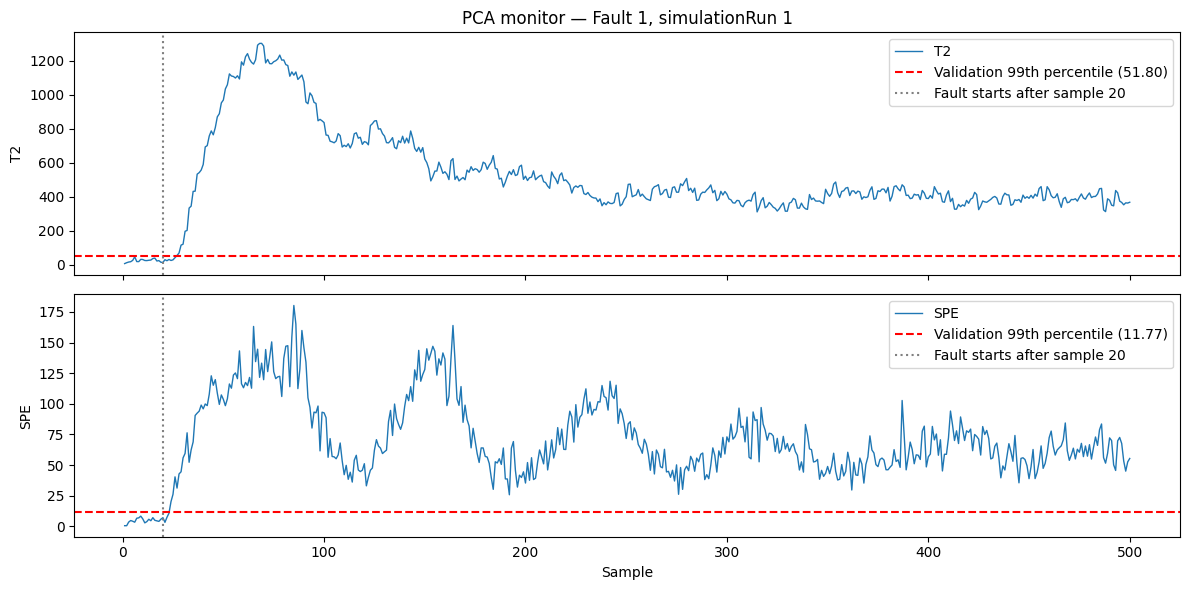

In [18]:
import matplotlib.pyplot as plt

run1 = scores.filter(
    (pl.col("faultNumber") == 1) & (pl.col("simulationRun") == 1)
).sort("sample")

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
for ax, column in ((axes[0], "T2"), (axes[1], "SPE")):
    threshold = threshold_lookup[column]
    ax.plot(run1["sample"], run1[column], lw=1, label=column)
    ax.axhline(
        threshold, color="red", linestyle="--",
        label=f"Validation 99th percentile ({threshold:.2f})",
    )
    ax.axvline(20, color="gray", linestyle=":", label="Fault starts after sample 20")
    ax.set_ylabel(column)
    ax.legend()
axes[0].set_title("PCA monitor — Fault 1, simulationRun 1")
axes[1].set_xlabel("Sample")
fig.tight_layout()
fig.savefig(results_dir / "pca_fault1_plot.png", dpi=150)
plt.show()